# 02 - Split train / validation / test e preprocessing

In questo notebook:
- divido le immagini in train (70%), validation (15%) e test (15%), stratificando per classe
- tengo ogni gruppo di foto quasi uguali (trovati in `01_eda`) tutto nello stesso set
- confronto con uno split casuale normale per vedere quanto leakage avrei avuto
- ridimensiono le immagini e normalizzo i pixel

Lo split viene salvato in `splits/split.csv`, così tutti i notebook successivi usano esattamente le stesse immagini.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

DATA_DIR = '../data.nosync/rockpaperscissors'
FIG_DIR = '../results/figures'
OUT_DIR = '../results/metrics'
CLASSES = ['paper', 'rock', 'scissors']
SEED = 42

df = pd.read_csv(OUT_DIR + '/image_inventory.csv')
print(len(df), 'immagini,', df['dup_group'].nunique(), 'gruppi')

2188 immagini, 1913 gruppi


## Split per gruppi

Nell'EDA ho collegato solo immagini della stessa classe, quindi ogni gruppo contiene una sola classe.
Questo semplifica molto lo split: per ogni classe mescolo i gruppi (con un seed fisso) e li assegno uno
alla volta al test finché arrivo al 15% delle immagini di quella classe, poi al validation fino a un altro
15%, e tutto il resto va nel train. Così lo split è stratificato per costruzione e nessun gruppo viene diviso.

In [2]:
# controllo che ogni gruppo abbia una sola classe
print('gruppi con più di una classe:', (df.groupby('dup_group')['label'].nunique() > 1).sum())

gruppi con più di una classe: 0


In [3]:
def split_per_gruppi(df, test_size=0.15, val_size=0.15, seed=SEED):
    rng = np.random.default_rng(seed)
    split = pd.Series('train', index=df.index)
    for c in CLASSES:
        dfc = df[df['label'] == c]
        dim_gruppi = dfc['dup_group'].value_counts()
        gruppi = np.sort(dfc['dup_group'].unique())   # ordine fisso prima di mescolare
        rng.shuffle(gruppi)
        n_test = test_size * len(dfc)
        n_val = val_size * len(dfc)
        conta_test, conta_val = 0, 0
        for g in gruppi:
            idx = dfc.index[dfc['dup_group'] == g]
            if conta_test + dim_gruppi[g] <= n_test:
                split[idx] = 'test'
                conta_test += dim_gruppi[g]
            elif conta_val + dim_gruppi[g] <= n_val:
                split[idx] = 'val'
                conta_val += dim_gruppi[g]
    return split

df['split'] = split_per_gruppi(df)
pd.crosstab(df['label'], df['split'], margins=True)[['train', 'val', 'test', 'All']]

split,train,val,test,All
label,,,,
paper,500,106,106,712
rock,510,108,108,726
scissors,526,112,112,750
All,1536,326,326,2188


Un gruppo entra nel test solo se non fa superare il 15%, altrimenti provo il validation, altrimenti
resta nel train. Siccome la maggior parte dei gruppi ha una sola foto, i gruppi piccoli riempiono i
buchi e le percentuali vengono quasi esatte. Controllo percentuali e che nessun gruppo sia diviso tra
due set.

In [4]:
tab = pd.crosstab(df['label'], df['split'], normalize='index')[['train', 'val', 'test']]
print((tab * 100).round(1))
print()
print('percentuale per set:', (df['split'].value_counts(normalize=True) * 100).round(1).to_dict())
print('gruppi divisi tra più set:', (df.groupby('dup_group')['split'].nunique() > 1).sum())
print('MD5 presenti in più set:', (df.groupby('md5')['split'].nunique() > 1).sum())

split     train   val  test
label                      
paper      70.2  14.9  14.9
rock       70.2  14.9  14.9
scissors   70.1  14.9  14.9

percentuale per set: {'train': 70.2, 'test': 14.9, 'val': 14.9}
gruppi divisi tra più set: 0
MD5 presenti in più set: 0


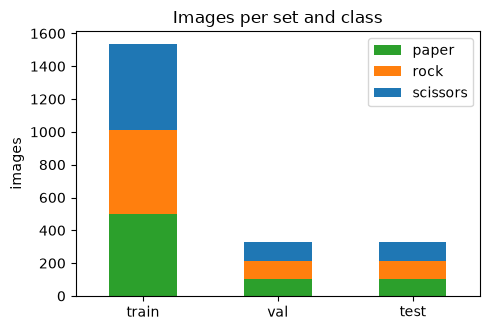

In [5]:
conteggi = pd.crosstab(df['split'], df['label']).loc[['train', 'val', 'test']]
conteggi.plot(kind='bar', stacked=True, figsize=(5, 3.4), color=['tab:green', 'tab:orange', 'tab:blue'], rot=0)
plt.ylabel('images')
plt.xlabel('')
plt.title('Images per set and class')
plt.legend(title='')
plt.tight_layout()
plt.savefig(FIG_DIR + '/split_class_distribution.png', dpi=150)
plt.show()

## Quanto leakage avrei con uno split normale?

Provo a fare lo split come si fa di solito, con `train_test_split` stratificato ma senza guardare i
gruppi, e conto quante immagini del test hanno una "gemella" (stesso gruppo) nel train. Lo ripeto con
diversi seed per vedere che non è un caso.

In [6]:
def test_con_gemella(split):
    # immagini del test che hanno almeno un'immagine dello stesso gruppo nel train
    gruppi_train = set(df.loc[split == 'train', 'dup_group'])
    test = df[split == 'test']
    return test['dup_group'].isin(gruppi_train).sum(), len(test)

risultati = []
for seed in range(10):
    idx_train, idx_tmp = train_test_split(df.index, test_size=0.30, stratify=df['label'], random_state=seed)
    idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=df.loc[idx_tmp, 'label'], random_state=seed)
    split_casuale = pd.Series('train', index=df.index)
    split_casuale[idx_val] = 'val'
    split_casuale[idx_test] = 'test'
    k, n_test = test_con_gemella(split_casuale)
    risultati.append(k / n_test * 100)

k, n_test = test_con_gemella(df['split'])
print('split casuale: in media il %.1f%% del test ha una gemella nel train (min %.1f%%, max %.1f%%)'
      % (np.mean(risultati), np.min(risultati), np.max(risultati)))
print('split per gruppi: %d immagini su %d' % (k, n_test))

split casuale: in media il 15.2% del test ha una gemella nel train (min 13.4%, max 17.0%)
split per gruppi: 0 immagini su 326


Con uno split normale circa il 15% delle foto di test (una su sette) ha una quasi-copia nel train: per quelle foto il
modello potrebbe "ricordare" la risposta invece di riconoscere il gesto. Con lo split per gruppi sono zero.

## Salvataggio dello split

In [7]:
os.makedirs('../splits', exist_ok=True)
df[['filename', 'label', 'dup_group', 'split']].to_csv('../splits/split.csv', index=False)
df['split'].value_counts()

split
train    1536
test      326
val       326
Name: count, dtype: int64

## Resize e normalizzazione

Le immagini originali sono 300x200. Le riduco a **150x100**, cioè metà, mantenendo il rapporto 3:2 così
la mano non viene deformata. È abbastanza per riconoscere la forma della mano e il training è molto più
veloce. MobileNet (più avanti) userà la sua dimensione di input.

Per la normalizzazione divido i pixel per 255, così i valori vanno da 0 a 1. È una trasformazione fissa,
non usa statistiche calcolate sui dati, quindi non c'è rischio di far "vedere" il test al modello.

In [8]:
W, H = 150, 100

def carica(righe):
    X = np.array([np.array(Image.open(os.path.join(DATA_DIR, l, f)).convert('RGB').resize((W, H), Image.BILINEAR))
                  for f, l in zip(righe['filename'], righe['label'])])
    y = np.array([CLASSES.index(l) for l in righe['label']])
    return X, y

X_train, y_train = carica(df[df['split'] == 'train'])
X_val, y_val = carica(df[df['split'] == 'val'])
X_test, y_test = carica(df[df['split'] == 'test'])
print('train', X_train.shape, 'val', X_val.shape, 'test', X_test.shape, X_train.dtype)

train (1536, 100, 150, 3) val (326, 100, 150, 3) test (326, 100, 150, 3) uint8


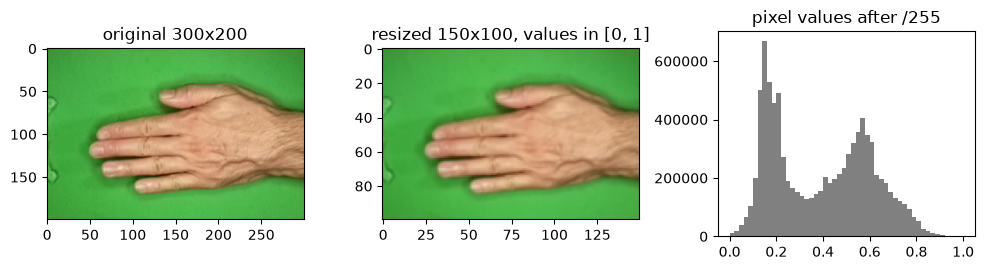

min 0.00  max 1.00  media 0.377


In [9]:
originale = Image.open(os.path.join(DATA_DIR, df['label'][0], df['filename'][0]))
X_norm = X_train.astype('float32') / 255

plt.figure(figsize=(10, 2.8))
plt.subplot(1, 3, 1)
plt.imshow(originale)
plt.title('original %dx%d' % originale.size)
plt.subplot(1, 3, 2)
plt.imshow(X_norm[0])
plt.title('resized %dx%d, values in [0, 1]' % (W, H))
plt.subplot(1, 3, 3)
plt.hist(X_norm[:200].flatten(), bins=50, color='grey')
plt.title('pixel values after /255')
plt.tight_layout()
plt.show()

print('min %.2f  max %.2f  media %.3f' % (X_norm.min(), X_norm.max(), X_norm.mean()))

Salvo gli array già ridimensionati (come interi 0-255, occupano 4 volte meno dei float) nella cartella dei
dati, che non va su GitHub. Nei notebook dei modelli li carico e divido per 255.

In [10]:
os.makedirs('../data.nosync/processed', exist_ok=True)
np.savez_compressed('../data.nosync/processed/rps_150x100.npz',
                    X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val, X_test=X_test, y_test=y_test)

## Nota sull'augmentation
L'augmentation (rotazioni, traslazioni, luminosità) la farò solo durante il training, con dei layer di Keras
che trasformano le immagini del train a ogni epoca. Le copie trasformate non vengono mai salvate, quindi
non possono finire nel validation o nel test.

## Riassunto
- split 70 / 15 / 15 stratificato per classe, con i gruppi di foto quasi uguali tenuti nello stesso set
- con uno split casuale circa il 15% delle foto di test avrebbe avuto una gemella nel train, con questo split 0
- immagini ridotte a 150x100 (rapporto 3:2), pixel normalizzati in [0, 1]
- split salvato in `splits/split.csv`, array in `data.nosync/processed/rps_150x100.npz`